# Dengue Symptoms, Fever and Exposure Factors Among Survey Participants in Bangladesh

**Course:** BDS3106 Programming for Data Science  |  **Project:** Mid-Term, Phase I

## 1. Problem and Why It Matters

Dengue is a serious public-health problem in Bangladesh. Hospital-based surveillance data from Bangladesh's health ministry recorded 321,179 dengue cases and 1,705 deaths in the 2023 outbreak [2]. WHO lists high fever, headache, body aches, nausea and rash as common symptoms, but also says many infections are mild or show no symptoms [1]. Symptoms alone cannot diagnose dengue, so it is useful to look at how symptoms and exposure factors differ between people who tested positive and people who tested negative.

This project uses a survey dataset of 1,018 participants with a recorded dengue test result [3]. It describes and cleans the data and then compares the two outcome groups. The analysis is **descriptive only**: no hypothesis tests, no prediction, no medical advice, and no estimate of dengue prevalence in Bangladesh.

## 2. Research Objectives and Questions

**Objectives**
1. Inspect the raw survey data, document its quality problems and justify each cleaning decision.
2. Compare fever duration and maximum temperature between recorded-positive and recorded-negative participants.
3. Describe how early symptoms, pain scores and vomiting frequency differ between the two groups.
4. Describe how the positive share varies with household exposure, stagnant water, area type and previous dengue infection, and state the limits of these comparisons.

**Main question:** How do early symptoms, fever characteristics and reported exposure factors differ between dengue-positive and dengue-negative participants?

1. **RQ1:** How do fever duration and maximum temperature differ between the two groups?
2. **RQ2:** Which of the eight early symptoms show the largest difference in frequency between the groups?
3. **RQ3:** How do the four pain scores (0 to 10) and daily vomiting episodes differ between the groups?
4. **RQ4:** How does the dengue-positive proportion vary with household exposure, stagnant water, area type and previous dengue infection?

`vomiting_per_day` is a count of episodes, not a severity score, so it is reported separately from the pain scores.

## 3. Dataset and Ethics

| Item | Detail |
|---|---|
| Title | Early Detection of Dengue Infection Using Machine Learning: A Survey Dataset from Bangladesh |
| Authors | Md Niazul Islam Naim, Abir Hasan |
| Source | Mendeley Data, Version 1, [doi:10.17632/t2h5528tc4.1](https://doi.org/10.17632/t2h5528tc4.1) |
| Licence | CC BY 4.0 (attribution required) |
| Size | 1,018 rows, 23 columns |
| Local file | `data/raw/Dengue_Raw_Research_Data_v1.csv` (not redistributed in the repository) |

The dataset is real survey data in its raw form. It contains no names or contact details. Points to keep in mind:
- Answers are self-reported and the test results were not verified against laboratory records. The test type and the timing of the test are not given [3].
- Timestamp, consent and data-entry role were removed from the public file, so consent cannot be checked.
- 23 participants are under 18, so results are reported in groups and not for very small districts.
- The sample is not random, so results describe these participants only.

## 4. Setup and Loading the Data

In [15]:
from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Default plot style
plt.rcParams["figure.figsize"] = (9, 5)

# Fixed colours and order for the two outcome groups, reused in every chart
COLORS = {"Positive": "#d9534f", "Negative": "#5bc0de"}
ORDER = ["Positive", "Negative"]

In [16]:
# The notebook lives in notebooks/, so the project root is one folder up
# (when run from the root folder itself, the current folder is used)
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Raw input file and output folder, built relative to the project root
raw_path = PROJECT_DIR / "data" / "raw" / "Dengue_Raw_Research_Data_v1.csv"
out_dir = PROJECT_DIR / "data"

if not raw_path.exists():
    raise FileNotFoundError(f"Raw data not found at {raw_path}. Place the CSV in data/raw/ (see README.md).")

# Load the raw file into a DataFrame; df_raw is not modified anywhere in this notebook
df_raw = pd.read_csv(raw_path)
print("Rows, columns:", df_raw.shape)

Rows, columns: (1018, 23)


## 5. Data Understanding

In [17]:
# First five records
df_raw.head()

,age,gender,district,area_type,ever_dengue,household_dengue_exposure_14d,stagnant_water,fever_days,max_temperature_f,headache_severity,...,vomiting_per_day,early_nausea,early_rash,early_bleeding,early_abdominal_pain,early_fatigue,early_appetite_loss,early_chills,early_diarrhea,dengue_result
0,30,Male (পুরুষ),Naogaon,Municipality / Semi-urban Area (পৌরসভা / আধা-শ...,No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),4,103,7,...,2,Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Yes (হ্যাঁ),Dengue Positive (ডেঙ্গু পজিটিভ)
1,38,Male (পুরুষ),Shariatpur,Municipality / Semi-urban Area (পৌরসভা / আধা-শ...,No (না),No (না),Yes (হ্যাঁ),9,105,9,...,6,Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Yes (হ্যাঁ),Dengue Positive (ডেঙ্গু পজিটিভ)
2,27,Male (পুরুষ),Munshiganj,Village / Rural Area (গ্রাম / পল্লি অঞ্চল),No (না),No (না),Yes (হ্যাঁ),5,107,10,...,6,Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Dengue Positive (ডেঙ্গু পজিটিভ)
3,35,Male (পুরুষ),Madaripur,Municipality / Semi-urban Area (পৌরসভা / আধা-শ...,No (না),No (না),No (না),13,104,10,...,1,Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Dengue Positive (ডেঙ্গু পজিটিভ)
4,44,Male (পুরুষ),Faridpur,Municipality / Semi-urban Area (পৌরসভা / আধা-শ...,No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),7,106,6,...,5,Yes (হ্যাঁ),No (না),No (না),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),Yes (হ্যাঁ),No (না),Dengue Negative (ডেঙ্গু নেগেটিভ)


In [18]:
# Column names, data types and non-null counts
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1018 entries, 0 to 1017
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   age                            1018 non-null   int64
 1   gender                         1018 non-null   str  
 2   district                       1018 non-null   str  
 3   area_type                      1018 non-null   str  
 4   ever_dengue                    1018 non-null   str  
 5   household_dengue_exposure_14d  1018 non-null   str  
 6   stagnant_water                 1018 non-null   str  
 7   fever_days                     1018 non-null   int64
 8   max_temperature_f              1006 non-null   str  
 9   headache_severity              1018 non-null   int64
 10  retro_orbital_pain             1018 non-null   int64
 11  muscle_pain                    1018 non-null   int64
 12  joint_pain                     1018 non-null   int64
 13  vomiting_per_day             

The 23 columns fall into these groups:

| Group | Columns | Type |
|---|---|---|
| Demographics | `age`, `gender`, `district`, `area_type` | number / text |
| Exposure | `ever_dengue`, `household_dengue_exposure_14d`, `stagnant_water` | text (Yes / No / Not sure) |
| Fever | `fever_days`, `max_temperature_f` | number, but temperature is stored as text |
| Pain scores (0 to 10) | `headache_severity`, `retro_orbital_pain`, `muscle_pain`, `joint_pain` | number |
| Vomiting count | `vomiting_per_day` | number |
| Early symptoms | `early_nausea`, `early_rash`, `early_bleeding`, `early_abdominal_pain`, `early_fatigue`, `early_appetite_loss`, `early_chills`, `early_diarrhea` | text (Yes / No) |
| Outcome | `dengue_result` | text (Positive / Negative) |

Text answers are bilingual, for example `Male (পুরুষ)`. A small helper keeps only the English part. `max_temperature_f` is stored as text, so some entries may not be valid numbers.

In [19]:
# Column groups used throughout the notebook
pain_cols = ["headache_severity", "retro_orbital_pain", "muscle_pain", "joint_pain"]
num_cols = ["age", "fever_days", "vomiting_per_day"] + pain_cols

def english(label):
    # Keep the English part of a bilingual label: 'Male (পুরুষ)' -> 'Male'
    return str(label).split("(")[0].strip()

# Basic statistics of the numeric columns
df_raw[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1018.0,34.12,11.09,14.0,25.0,33.0,41.0,71.0
fever_days,1018.0,6.56,2.33,0.0,5.0,6.0,8.0,16.0
vomiting_per_day,1018.0,1.98,1.55,0.0,0.0,2.0,3.0,6.0
headache_severity,1018.0,8.51,1.70,0.0,8.0,9.0,10.0,10.0
retro_orbital_pain,1018.0,4.25,3.59,0.0,0.0,5.0,7.0,10.0
muscle_pain,1018.0,7.44,2.05,0.0,6.0,8.0,9.0,10.0
joint_pain,1018.0,6.89,2.55,0.0,5.0,8.0,9.0,10.0


## 6. Data Exploration

The raw data is summarised with tables and charts to show the shape of each variable, how common each symptom is, and how variables relate to each other. Nothing is modified in this section.

### 6.1 Descriptive Summary

In [20]:
# Numeric variables: centre, spread, skewness and count of values outside the IQR fences
desc = df_raw[num_cols].describe().T
desc["median"] = df_raw[num_cols].median()
desc["IQR"] = desc["75%"] - desc["25%"]
desc["skewness"] = df_raw[num_cols].skew()

low = desc["25%"] - 1.5 * desc["IQR"]
high = desc["75%"] + 1.5 * desc["IQR"]
desc["IQR outliers"] = [((df_raw[c] < low[c]) | (df_raw[c] > high[c])).sum() for c in num_cols]

desc[["count", "mean", "std", "min", "25%", "median", "75%", "max", "IQR", "skewness", "IQR outliers"]].round(2)

,count,mean,std,min,25%,median,75%,max,IQR,skewness,IQR outliers
age,1018.0,34.12,11.09,14.0,25.0,33.0,41.0,71.0,16.0,0.59,6
fever_days,1018.0,6.56,2.33,0.0,5.0,6.0,8.0,16.0,3.0,0.80,19
vomiting_per_day,1018.0,1.98,1.55,0.0,0.0,2.0,3.0,6.0,3.0,0.22,0
headache_severity,1018.0,8.51,1.70,0.0,8.0,9.0,10.0,10.0,2.0,-1.30,17
retro_orbital_pain,1018.0,4.25,3.59,0.0,0.0,5.0,7.0,10.0,7.0,0.01,0
muscle_pain,1018.0,7.44,2.05,0.0,6.0,8.0,9.0,10.0,3.0,-1.32,27
joint_pain,1018.0,6.89,2.55,0.0,5.0,8.0,9.0,10.0,4.0,-1.07,0


In [21]:
# Share of participants who gave the lowest, middle and highest pain score
pd.DataFrame({
    "% scored 0": (df_raw[pain_cols] == 0).mean() * 100,
    "% scored 5": (df_raw[pain_cols] == 5).mean() * 100,
    "% scored 10": (df_raw[pain_cols] == 10).mean() * 100,
}).round(1)

,% scored 0,% scored 5,% scored 10
headache_severity,0.4,4.9,39.9
retro_orbital_pain,35.8,14.1,7.6
muscle_pain,2.7,13.9,11.8
joint_pain,5.7,16.3,13.2


In [22]:
# Categorical variables: count and percentage of each category (English label only)
cat_cols = ["dengue_result", "gender", "area_type", "ever_dengue",
            "household_dengue_exposure_14d", "stagnant_water"]

freq = pd.concat({c: df_raw[c].map(english).value_counts().to_frame("n") for c in cat_cols},
                 names=["variable", "category"])
freq["%"] = (freq["n"] / len(df_raw) * 100).round(2)
freq

n      %
variable                      category                                  
dengue_result                 Dengue Positive                 630  61.89
                              Dengue Negative                 388  38.11
gender                        Male                            767  75.34
                              Female                          251  24.66
area_type                     City Corporation / Urban Area   837  82.22
                              Municipality / Semi-urban Area   96   9.43
                              Village / Rural Area             85   8.35
ever_dengue                   No                              954  93.71
                              Yes                              64   6.29
household_dengue_exposure_14d No                              764  75.05
                              Yes                             247  24.26
                              Not sure                          7   0.69
stagnant_water                Yes                             747  73.38
                              No                              173  16.99
                              Not sure                         98   9.63

In [23]:
# Early symptoms: percentage of all participants who answered "Yes"
symptom_cols = ["early_nausea", "early_rash", "early_bleeding", "early_abdominal_pain",
                "early_fatigue", "early_appetite_loss", "early_chills", "early_diarrhea"]

symptom_pct = (df_raw[symptom_cols].apply(lambda s: s.str.startswith("Yes")).mean() * 100).round(2)
symptom_pct.index = symptom_pct.index.str.replace("early_", "")
symptom_pct.sort_values(ascending=False).to_frame("% Yes")

,% Yes
nausea,86.15
fatigue,77.31
appetite_loss,72.79
chills,55.80
diarrhea,49.12
abdominal_pain,35.85
rash,22.00
bleeding,5.50


In [24]:
# Temperature is stored as text; convert to numbers (entries that are not numbers become NaN)
temp_text = df_raw["max_temperature_f"]
temp_num = pd.to_numeric(temp_text, errors="coerce")

print("Numeric temperature entries:", temp_num.notna().sum())
print(f"Minimum / median / maximum: {temp_num.min():g} / {temp_num.median():g} / {temp_num.max():g}")
print("Entries between 99 and 106 °F:", temp_num.between(99, 106).sum())
print()

# District distribution after trimming spaces
district_counts = df_raw["district"].str.strip().value_counts()
print("Distinct district values in the raw file:", df_raw["district"].nunique())
print("Distinct district values after trimming spaces:", district_counts.size)
print(f"Largest district: {district_counts.index[0]} ({district_counts.iloc[0] / len(df_raw):.1%})")
print("Districts with fewer than 10 participants:", (district_counts < 10).sum())

Numeric temperature entries: 1005
Minimum / median / maximum: 8 / 103 / 107
Entries between 99 and 106 °F: 1002

Distinct district values in the raw file: 28
Distinct district values after trimming spaces: 20
Largest district: Dhaka (71.1%)
Districts with fewer than 10 participants: 13


**Descriptive findings**
- **Numeric variables:** Ages run from 14 to 71 (median 33). Fever lasts a median of 6 days (0 to 16). Vomiting is 0 to 6 episodes a day, and about 27% report none. All pain scores stay inside 0 to 10.
- **Skew and ceiling effect:** Headache, muscle pain and joint pain are skewed towards high scores (skewness about -1), and about 40% of participants rated headache as 10. Retro-orbital pain is flatter, with about 36% giving 0. Medians and IQR therefore describe these scores better than means.
- **IQR outliers:** The flagged values (fever of 13 to 16 days, ages over 65, low pain scores) are plausible survey answers.
- **Categories:** 630 participants are positive and 388 negative. 75% are male, 82% are urban, and only 64 report a previous dengue infection.
- **Hidden uncertainty:** 98 participants answered "Not sure" about stagnant water. This is not a missing value, so a missing-value count does not show it.
- **Symptoms:** Nausea (86%), fatigue (77%) and appetite loss (73%) are the most common. Rash (22%) and bleeding (5.5%) are the least common.

### 6.2 Visual Summary

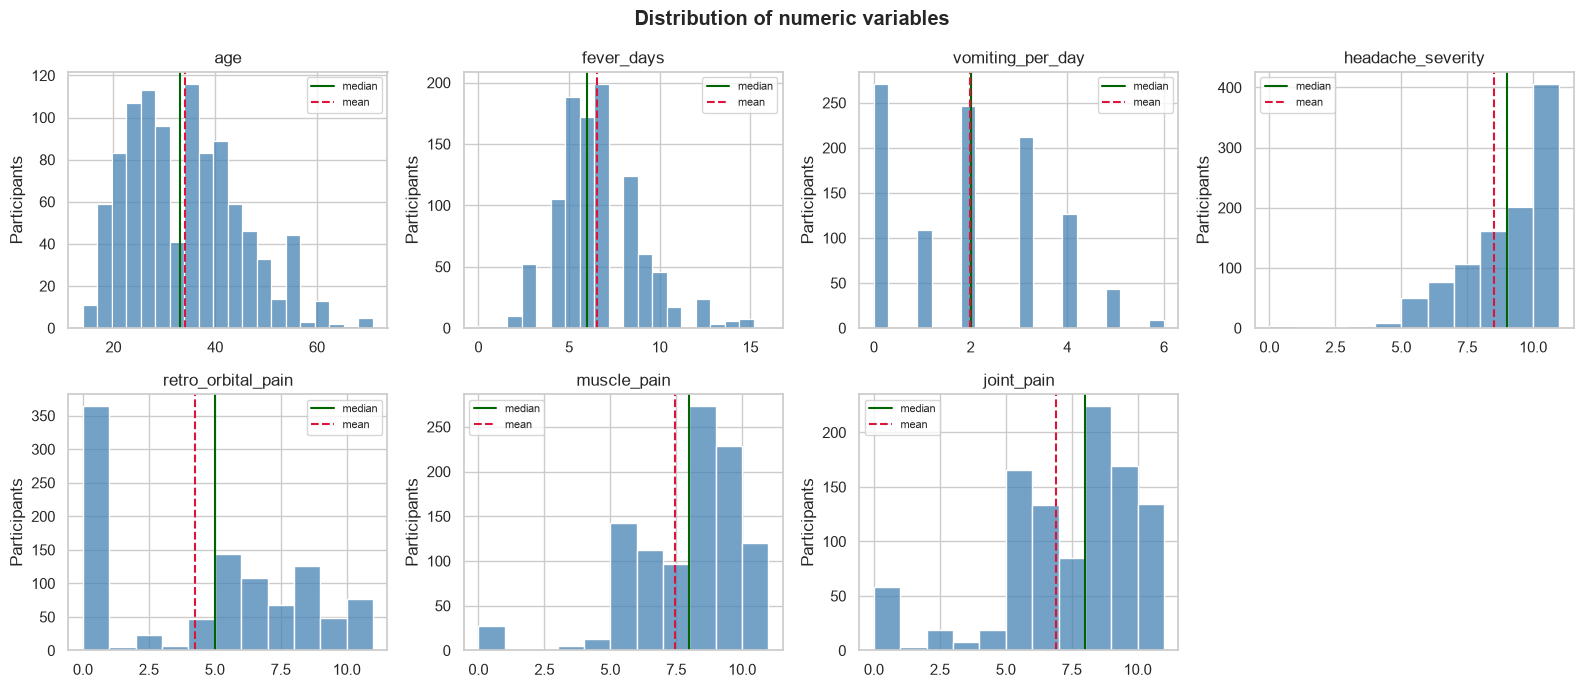

In [25]:
# Histogram of every numeric variable with mean and median marked
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df_raw[col], bins=range(0, 12) if col in pain_cols else 20, color="steelblue", ax=ax)
    ax.axvline(df_raw[col].median(), color="darkgreen", label="median")
    ax.axvline(df_raw[col].mean(), color="crimson", linestyle="--", label="mean")
    ax.set(title=col, xlabel="", ylabel="Participants")
    ax.legend(fontsize=8)
axes.ravel()[-1].axis("off")
plt.suptitle("Distribution of numeric variables", fontweight="bold")
plt.tight_layout()
plt.show()

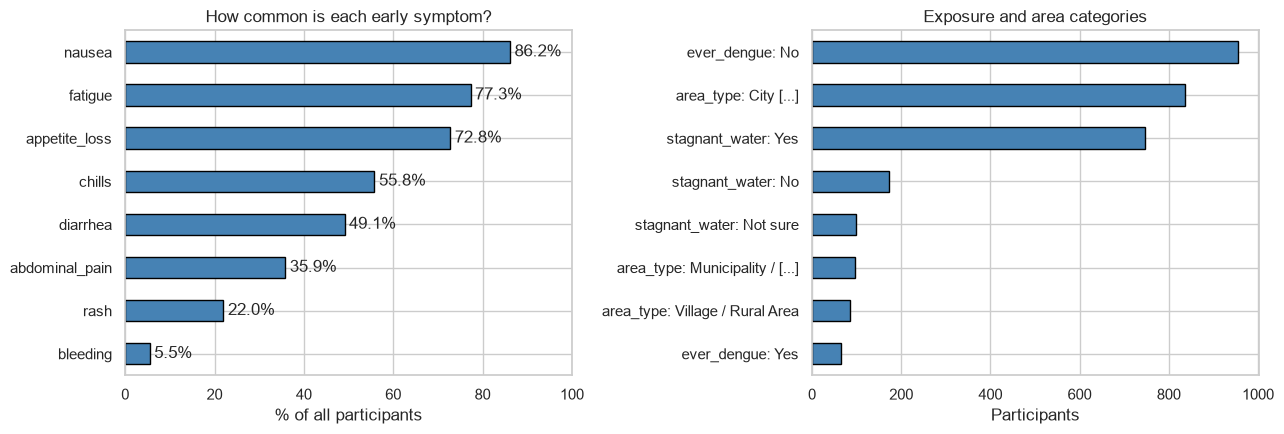

In [26]:
# Left: frequency of each early symptom. Right: size of each exposure and area category
symptom_sorted = symptom_pct.sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
symptom_sorted.plot.barh(color="steelblue", edgecolor="black", ax=axes[0])
for i, v in enumerate(symptom_sorted):
    axes[0].text(v + 1, i, f"{v:.1f}%", va="center")
axes[0].set(title="How common is each early symptom?", xlabel="% of all participants", xlim=(0, 100))

cat_counts = pd.concat({c: df_raw[c].map(english).value_counts() for c in ["stagnant_water", "ever_dengue", "area_type"]})
cat_counts.index = [f"{a}: {textwrap.shorten(b, 20)}" for a, b in cat_counts.index]
cat_counts.sort_values().plot.barh(color="steelblue", edgecolor="black", ax=axes[1])
axes[1].set(title="Exposure and area categories", xlabel="Participants")
plt.tight_layout()
plt.show()

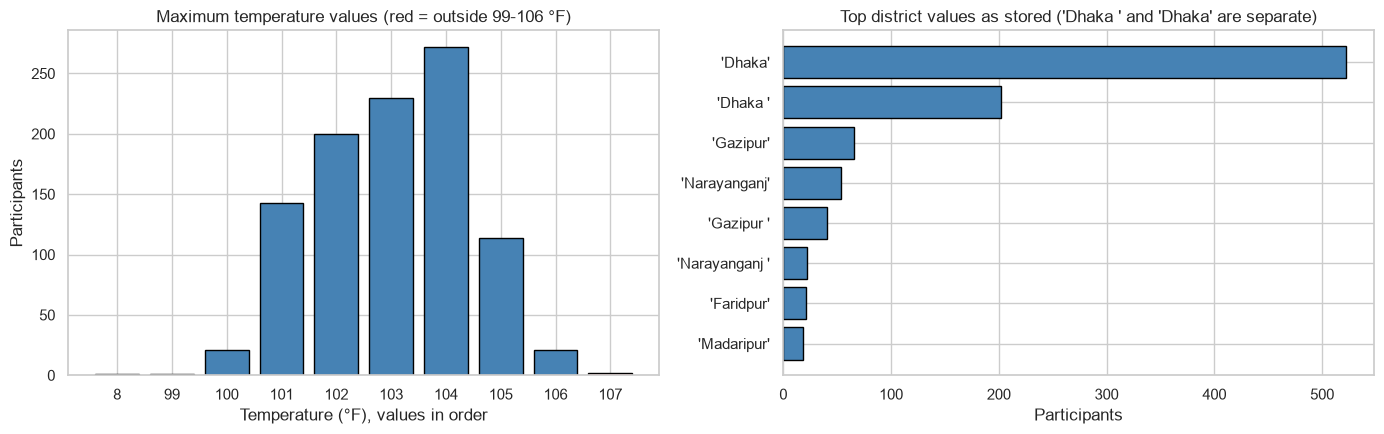

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: every numeric temperature value in order; an ordinal axis keeps the single value of 8 from squashing the chart
temp_counts = temp_num.value_counts().sort_index()
colors = ["#d9534f" if (v < 99 or v > 106) else "steelblue" for v in temp_counts.index]
axes[0].bar(range(len(temp_counts)), temp_counts.values, color=colors, edgecolor="black")
axes[0].set_xticks(range(len(temp_counts)))
axes[0].set_xticklabels([f"{v:g}" for v in temp_counts.index])
axes[0].set(title="Maximum temperature values (red = outside 99-106 °F)", xlabel="Temperature (°F), values in order", ylabel="Participants")

# Right: the most frequent district strings as stored; trailing spaces split one district into two bars
raw_top = df_raw["district"].value_counts().head(8)
axes[1].barh([repr(d) for d in raw_top.index], raw_top.values, color="steelblue", edgecolor="black")
axes[1].invert_yaxis()
axes[1].set(title="Top district values as stored ('Dhaka ' and 'Dhaka' are separate)", xlabel="Participants")

plt.tight_layout()
plt.show()

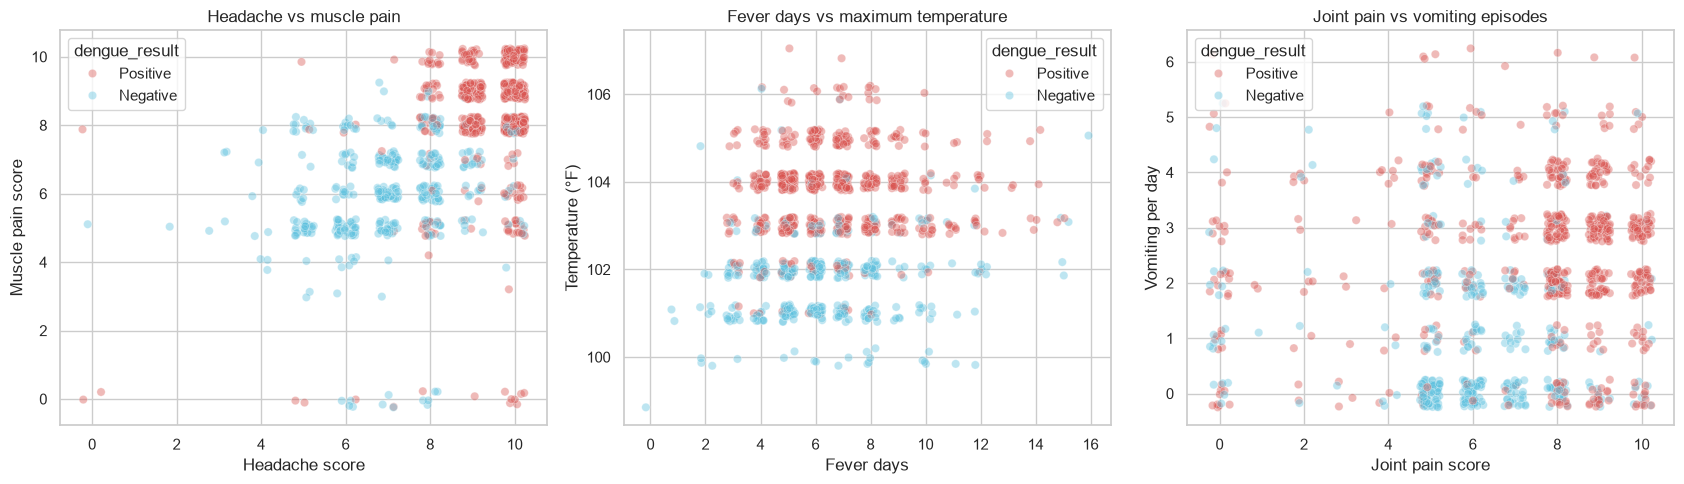

In [28]:
# Short outcome label (Positive / Negative) for colouring the scatterplots
outcome_raw = df_raw["dengue_result"].map(english).str.replace("Dengue ", "", regex=False)

# Small random offset so overlapping whole-number scores stay visible
rng = np.random.default_rng(42)
jitter = lambda s: s + rng.uniform(-0.25, 0.25, len(s))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.scatterplot(x=jitter(df_raw["headache_severity"]), y=jitter(df_raw["muscle_pain"]),
                hue=outcome_raw, palette=COLORS, alpha=0.4, ax=axes[0])
axes[0].set(title="Headache vs muscle pain", xlabel="Headache score", ylabel="Muscle pain score")

# Temperatures below 90 °F are left out of this plot so the axis stays readable
sns.scatterplot(x=jitter(df_raw["fever_days"]), y=temp_num.where(temp_num >= 90) + rng.uniform(-0.2, 0.2, len(df_raw)),
                hue=outcome_raw, palette=COLORS, alpha=0.4, ax=axes[1])
axes[1].set(title="Fever days vs maximum temperature", xlabel="Fever days", ylabel="Temperature (°F)")

sns.scatterplot(x=jitter(df_raw["joint_pain"]), y=jitter(df_raw["vomiting_per_day"]),
                hue=outcome_raw, palette=COLORS, alpha=0.4, ax=axes[2])
axes[2].set(title="Joint pain vs vomiting episodes", xlabel="Joint pain score", ylabel="Vomiting per day")

plt.tight_layout()
plt.show()

**Visual findings**
- **Distributions:** Age and fever days are right-skewed, and pain scores pile up near 10.
- **Irregularities:** The temperature chart shows three values outside the 99 to 106 °F range (one 8 and two 107). The district chart shows one district split into two bars by a trailing space. Both are examined in the next section.
- **Relationships:** Scatterplot points overlap heavily because scores are whole numbers. The positive group sits towards higher pain scores and higher temperature, but the groups overlap. No pair of numeric variables reaches |rho| of 0.70. The strongest are joint pain with muscle pain (about 0.61), temperature with headache (about 0.57) and muscle pain with headache (about 0.56). The correlations are moderate, so all variables are kept.
- These are descriptive patterns, not causes.

## 7. Data Cleaning

Cleaning follows three steps. First every issue is counted in the raw data. Then only the fixes that can be justified are applied to a separate copy. Finally the counts are repeated to confirm the result.

### 7.1 Inspecting the Raw Data

In [29]:
# Missing values in each column
missing = df_raw.isna().sum()
print("Columns with missing values:")
print(missing[missing > 0].to_string())
print()

# Rows that are identical in every column
print("Duplicate rows:", df_raw.duplicated().sum())

Columns with missing values:
max_temperature_f    12

Duplicate rows: 0


In [30]:
# Text format audit of every non-numeric column:
# extra spaces, spelling that differs only by letter case, and bilingual labels
text_cols = [c for c in df_raw.columns if not pd.api.types.is_numeric_dtype(df_raw[c])]

audit = []
for col in text_cols:
    s = df_raw[col].dropna().astype(str)
    trimmed = s.str.strip()
    audit.append({
        "column": col,
        "distinct values": s.nunique(),
        "values with extra spaces": (s != trimmed).sum(),
        "case-only variants": trimmed.nunique() - trimmed.str.lower().nunique(),
        "bilingual labels": s.str.contains("(", regex=False).sum(),
    })
pd.DataFrame(audit)

,column,distinct values,values with extra spaces,case-only variants,bilingual labels
0,gender,2,0,0,1018
1,district,28,296,1,0
2,area_type,3,0,0,1018
3,ever_dengue,2,0,0,1018
4,household_dengue_exposure_14d,3,0,0,1018
5,stagnant_water,3,0,0,1018
6,max_temperature_f,11,0,0,0
7,early_nausea,2,0,0,1018
8,early_rash,2,0,0,1018
9,early_bleeding,2,0,0,1018


In [31]:
# Temperature column: entries that are missing, non-numeric or outside the expected range
print("Missing entries:", temp_text.isna().sum())
print("Non-numeric entries:", temp_text[temp_num.isna() & temp_text.notna()].tolist())
print("Values <= 90 °F:", temp_num[temp_num <= 90].tolist())
print("Values >= 107 °F:", temp_num[temp_num >= 107].tolist())

# Range of the numeric entries that remain once the three extreme values are set aside
core = temp_num[(temp_num > 90) & (temp_num < 107)]
print(f"Entries between the extremes: {core.size} (lowest {core.min():g} °F, highest {core.max():g} °F)")

Missing entries: 12
Non-numeric entries: ['Munshiganj']
Values <= 90 °F: [8.0]
Values >= 107 °F: [107.0, 107.0]
Entries between the extremes: 1002 (lowest 99 °F, highest 106 °F)


In [32]:
# District column: extra spaces, and names that remain after trimming
district = df_raw["district"]
print("Distinct raw values:", district.nunique())
print("Values with extra spaces:", (district != district.str.strip()).sum())
print()
print(district.str.strip().value_counts().to_string())

Distinct raw values: 28
Values with extra spaces: 296

district
Dhaka          724
Gazipur        107
Narayanganj     76
Faridpur        38
Madaripur       20
Munshiganj      19
Manikganj       11
Shariatpur       7
Mymensingh       4
Cumilla          2
Naogaon          1
Munsiganj        1
Narsingdi        1
gazipur          1
Barishal         1
Tangail          1
Chadpur          1
Lakshmipur       1
Noakhali         1
Kishorganj       1


Names such as `Dhaka ` and `Dhaka` differ only by a trailing space. In addition, four names are spelling variants of another district: `gazipur`, `Munsiganj`, `Chadpur` and `Kishorganj`.

In [33]:
# Remaining checks: zero fever days, "Not sure" answers and pain scores outside 0-10
print("Participants with fever_days = 0:", (df_raw["fever_days"] == 0).sum())
print("Pain scores outside 0-10:", ((df_raw[pain_cols] < 0) | (df_raw[pain_cols] > 10)).sum().sum())

for col in ["stagnant_water", "household_dengue_exposure_14d"]:
    n = df_raw[col].str.startswith("Not sure").sum()
    print(f"'Not sure' answers in {col}: {n} ({n / len(df_raw):.1%})")

Participants with fever_days = 0: 2
Pain scores outside 0-10: 0
'Not sure' answers in stagnant_water: 98 (9.6%)
'Not sure' answers in household_dengue_exposure_14d: 7 (0.7%)


**Issues found and decisions**

| Issue | Column | Records | Decision |
|---|---|---|---|
| Missing temperature | `max_temperature_f` | 12 | Keep missing, do not impute |
| Text in a numeric column (`Munshiganj`) | `max_temperature_f` | 1 | Keep, exclude from temperature analysis |
| Implausible value (8 °F) | `max_temperature_f` | 1 | Keep, exclude from temperature analysis |
| Very high value (107 °F) | `max_temperature_f` | 2 | Keep, test in a sensitivity run |
| Trailing spaces in district | `district` | 296 | Trim in the cleaned copy |
| District spelling variants | `district` | 4 | Map to the standard spelling |
| `fever_days = 0` | `fever_days` | 2 | Keep; describe everyone as "participants", not "fever patients" |
| "Not sure" answers | `stagnant_water`, `household_dengue_exposure_14d` | 98, 7 | Keep as their own category |
| Duplicate rows | all columns | 0 | Nothing to remove |
| Bilingual labels | all categorical columns | all | Keep; the English part is extracted when needed |

No rows are deleted. The data has no participant ID, so identical rows could still be different people and cannot be removed safely.

### 7.2 Applying the Cleaning Steps

All changes are made on a copy named `df`:
- `district` is trimmed and the four spelling variants are corrected. The original value is kept in `district_original`.
- `outcome` is a short English version of `dengue_result` (Positive / Negative).
- `temp_f` is the temperature as a number; entries that are not numbers become NaN. The main temperature analysis uses 99 to 106 °F, which covers 1,002 of the 1,005 numeric entries (the reason for this range is given in Section 8.2). It is an analysis window, not a medical definition of fever.

In [34]:
# Mapping from the four misspelled district names to the standard spelling
spelling_fix = {"gazipur": "Gazipur", "Munsiganj": "Munshiganj",
                "Chadpur": "Chandpur", "Kishorganj": "Kishoreganj"}

# Work on a copy so the raw DataFrame stays unchanged
df = df_raw.copy()

# Keep the original district text, then trim spaces and apply the spelling mapping
df["district_original"] = df["district"]
df["district"] = df["district"].str.strip().replace(spelling_fix)

# Short outcome label and numeric temperature column
df["outcome"] = df["dengue_result"].map(english).str.replace("Dengue ", "", regex=False)
df["temp_f"] = pd.to_numeric(df["max_temperature_f"], errors="coerce")

# Integrity checks: no rows lost, two outcome groups, 18 districts, temperature text untouched
assert len(df) == len(df_raw) == 1018
assert set(df["outcome"]) == {"Positive", "Negative"}
assert df["district"].nunique() == 18
assert df["max_temperature_f"].equals(df_raw["max_temperature_f"])

print("District values changed:", (df["district"] != df["district_original"]).sum())

District values changed: 300


### 7.3 Verifying the Result

In [35]:
# Repeat the counts on the cleaned copy (original columns only) and compare with the raw data
original_cols = list(df_raw.columns)

def issue_counts(data):
    return {
        "rows": len(data),
        "missing cells": data[original_cols].isna().sum().sum(),
        "duplicate rows": data[original_cols].duplicated().sum(),
        "district values with extra spaces": (data["district"] != data["district"].str.strip()).sum(),
        "distinct district names": data["district"].nunique(),
    }

pd.DataFrame({"raw data": issue_counts(df_raw), "cleaned copy": issue_counts(df)})

,raw data,cleaned copy
rows,1018,1018
missing cells,12,12
duplicate rows,0,0
district values with extra spaces,296,0
distinct district names,28,18


Only the district column changed: 300 values were corrected (296 trailing spaces and 4 spelling variants) and the number of distinct district names fell from 28 to 18. Row count, missing values and duplicates are unchanged, and the temperature entries are kept exactly as recorded.

### 7.4 Saving the Cleaned Dataset

In [36]:
# Write the cleaned copy to a new CSV; the raw file is not touched
out_dir.mkdir(exist_ok=True)
df.to_csv(out_dir / "Dengue_working_copy.csv", index=False)
print("Saved to", out_dir / "Dengue_working_copy.csv")

Saved to C:\Users\User\Desktop\dengue-symptom-exposure-analysis-main\data\Dengue_working_copy.csv


## 8. Analysis of the Research Questions

The comparisons below use the cleaned copy `df`.

### 8.1 Sample Overview

Positive: 630 (61.89%)   Negative: 388 (38.11%)
Male: 75.3%
Urban: 82.2%
Dhaka district: 71.1%
Age range: 14 to 71, median 33; under 18: 23


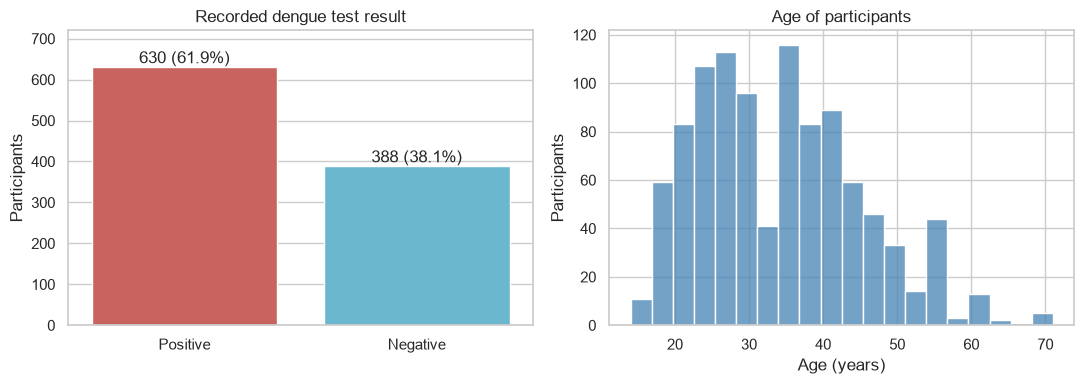

In [37]:
# Counts and percentages of each outcome group, plus basic sample characteristics
n_pos = (df["outcome"] == "Positive").sum()
n_neg = (df["outcome"] == "Negative").sum()
print(f"Positive: {n_pos} ({n_pos / len(df):.2%})   Negative: {n_neg} ({n_neg / len(df):.2%})")
print(f"Male: {df['gender'].str.startswith('Male').mean():.1%}")
print(f"Urban: {df['area_type'].str.startswith('City').mean():.1%}")
print(f"Dhaka district: {(df['district'] == 'Dhaka').mean():.1%}")
print(f"Age range: {df['age'].min()} to {df['age'].max()}, median {df['age'].median():.0f}; under 18: {(df['age'] < 18).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = df["outcome"].value_counts()[ORDER]
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=COLORS, legend=False, ax=axes[0])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 10, f"{v} ({v / len(df):.1%})", ha="center")
axes[0].set(title="Recorded dengue test result", xlabel="", ylabel="Participants", ylim=(0, 720))

sns.histplot(df["age"], bins=20, color="steelblue", ax=axes[1])
axes[1].set(title="Age of participants", xlabel="Age (years)", ylabel="Participants")

plt.tight_layout()
plt.show()

About 62% of participants tested positive, but this describes the dataset and **not** dengue prevalence in Bangladesh. Most participants are male, urban and from Dhaka (71%), and most are adults (23 are under 18).

### 8.2 RQ1: Fever Duration and Maximum Temperature

Fever duration uses all 1,018 participants. Temperature uses only entries from 99 to 106 °F (about 37.2 to 41.1 °C), which keeps 1,002 of the 1,005 numeric entries.

**Why this window:** it is a data-quality window, not a clinical definition of fever. Apart from three entries, the numeric temperatures form one continuous group between 99 and 106 °F. The three exceptions are one value of 8 °F, which cannot be a body temperature, and two values of 107 °F (about 41.7 °C), which lie above all other entries. These three are therefore left out of the main comparison. Because the 107 °F values could still be genuine, a second run that includes them (99 to 107 °F) checks that the choice does not change the result.

In total 16 records are not used for the temperature comparison: 12 missing, 1 text entry, 1 at 8 °F and 2 at 107 °F.

In [38]:
def summarize(data, col):
    # n, median, IQR, mean and range of one column for each outcome group
    g = data.groupby("outcome")[col]
    out = pd.DataFrame({"n": g.count(), "median": g.median(),
                        "IQR": g.quantile(0.75) - g.quantile(0.25),
                        "mean": g.mean(), "min": g.min(), "max": g.max()})
    return out.loc[ORDER].round(2)

# Rows whose temperature lies in the 99-106 °F analysis window
df_temp = df[df["temp_f"].between(99, 106)]

print("Fever duration (days)")
display(summarize(df, "fever_days"))
print("Maximum temperature (°F), 99-106 window")
display(summarize(df_temp, "temp_f"))

# Sensitivity run: repeat the median comparison with the two 107 °F values included
df_temp_107 = df[df["temp_f"].between(99, 107)]
print("Median temperature with 107 °F values included:")
print(df_temp_107.groupby("outcome")["temp_f"].median().loc[ORDER].to_string())

Fever duration (days)


,n,median,IQR,mean,min,max
outcome,,,,,,
Positive,630,7.0,3.0,6.73,3,15
Negative,388,6.0,3.0,6.28,0,16


Maximum temperature (°F), 99-106 window


,n,median,IQR,mean,min,max
outcome,,,,,,
Positive,624,104.0,1.0,103.77,101.0,106.0
Negative,378,102.0,1.0,101.75,99.0,106.0


Median temperature with 107 °F values included:
outcome
Positive    104.0
Negative    102.0


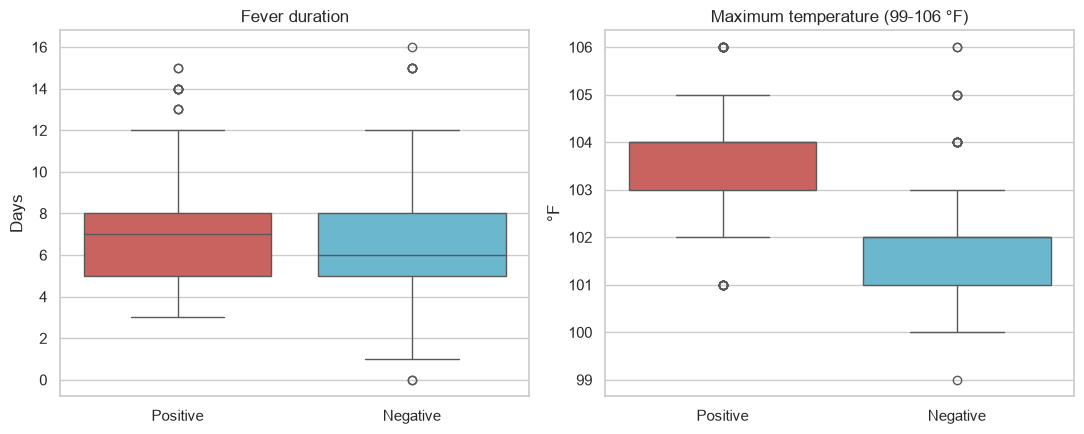

In [39]:
# Boxplots of fever duration and temperature by outcome
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.boxplot(data=df, x="outcome", y="fever_days", order=ORDER, hue="outcome",
            palette=COLORS, legend=False, ax=axes[0])
axes[0].set(title="Fever duration", xlabel="", ylabel="Days")

sns.boxplot(data=df_temp, x="outcome", y="temp_f", order=ORDER, hue="outcome",
            palette=COLORS, legend=False, ax=axes[1])
axes[1].set(title="Maximum temperature (99-106 °F)", xlabel="", ylabel="°F")

plt.tight_layout()
plt.show()

**Finding:** Fever duration is similar in both groups (median 7 days for positive and 6 for negative, IQR 3 in both). Temperature shows a clearer gap: the median is 104 °F for positive and 102 °F for negative participants. Including the two 107 °F values does not change either median.

### 8.3 RQ2: Early Symptoms

For each symptom, the percentage answering "Yes" is calculated within each group. The difference is *positive % minus negative %*, in percentage points (pp).

In [40]:
# English names for the eight symptom columns
symptom_names = {
    "early_appetite_loss": "Appetite loss", "early_fatigue": "Fatigue / weakness",
    "early_nausea": "Nausea", "early_bleeding": "Bleeding", "early_rash": "Rash",
    "early_diarrhea": "Diarrhea", "early_chills": "Chills / shivering",
    "early_abdominal_pain": "Abdominal pain",
}

# Percentage of "Yes" answers per outcome group, and the difference between the groups
yes = df[list(symptom_names)].apply(lambda s: s.str.startswith("Yes"))
rq2 = (yes.groupby(df["outcome"]).mean().T * 100)[ORDER]
rq2["Difference (pp)"] = rq2["Positive"] - rq2["Negative"]
rq2.index = rq2.index.map(symptom_names)
rq2 = rq2.sort_values("Difference (pp)", ascending=False).round(2)
rq2.columns = ["Positive (%)", "Negative (%)", "Difference (pp)"]
rq2

,Positive (%),Negative (%),Difference (pp)
Appetite loss,99.21,29.90,69.31
Fatigue / weakness,99.68,40.98,58.70
Nausea,98.73,65.72,33.01
Bleeding,7.14,2.84,4.31
Rash,21.11,23.45,-2.34
Chills / shivering,51.43,62.89,-11.46
Diarrhea,40.79,62.63,-21.84
Abdominal pain,23.33,56.19,-32.85


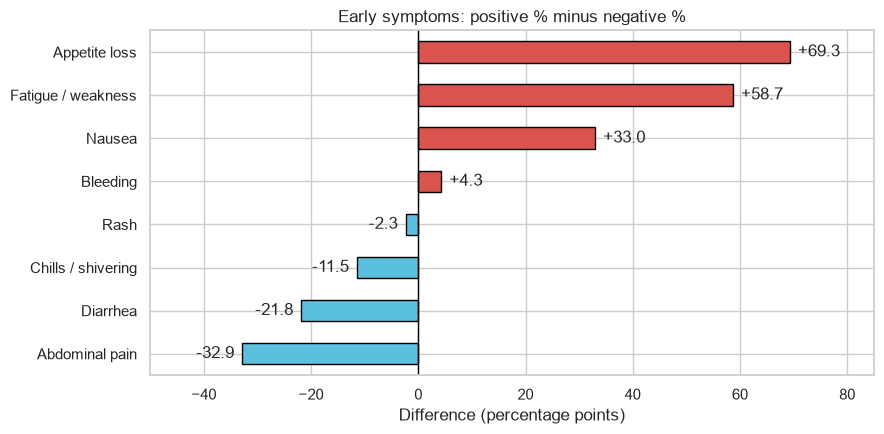

In [41]:
# Horizontal bars of the percentage-point difference; red = more common in positive, blue = more common in negative
colors = ["#d9534f" if d > 0 else "#5bc0de" for d in rq2["Difference (pp)"]]
ax = rq2["Difference (pp)"].plot.barh(color=colors, edgecolor="black", figsize=(9, 4.5))
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=1)
for i, d in enumerate(rq2["Difference (pp)"]):
    ax.text(d + (1.5 if d >= 0 else -1.5), i, f"{d:+.1f}", va="center", ha="left" if d >= 0 else "right")
ax.set(title="Early symptoms: positive % minus negative %", xlabel="Difference (percentage points)", ylabel="",
       xlim=(-50, 85))
plt.tight_layout()
plt.show()

**Finding:** Appetite loss (+69.3 pp), fatigue (+58.7 pp) and nausea (+33.0 pp) were much more common in the positive group. Abdominal pain (-32.9 pp), diarrhea (-21.8 pp) and chills (-11.5 pp) were more common in the negative group. Rash was similar in both groups and bleeding was rare (7.1% vs 2.8%).

### 8.4 RQ3: Pain Scores and Vomiting

Pain scores are skewed towards high values (39.9% of participants rated headache as 10), so medians and interquartile ranges (IQR) are reported alongside means.

In [42]:
def iqr(s):
    # Interquartile range: 75th percentile minus 25th percentile
    return s.quantile(0.75) - s.quantile(0.25)

# Median, IQR and mean of each pain score and of the vomiting count, by outcome
score_cols = pain_cols + ["vomiting_per_day"]
rq3 = df.groupby("outcome")[score_cols].agg(["median", iqr, "mean"]).loc[ORDER].T.round(2)
rq3.index = pd.MultiIndex.from_tuples([(c, s) for c, s in rq3.index], names=["variable", "statistic"])
rq3

outcome                       Positive  Negative
variable           statistic                    
headache_severity  median        10.00      7.00
                   iqr            1.00      2.00
                   mean           9.41      7.04
retro_orbital_pain median         6.00      3.00
                   iqr            8.00      6.00
                   mean           4.94      3.12
muscle_pain        median         9.00      6.00
                   iqr            1.00      2.00
                   mean           8.30      6.03
joint_pain         median         8.00      6.00
                   iqr            2.75      2.00
                   mean           7.46      5.97
vomiting_per_day   median         3.00      0.00
                   iqr            1.00      2.00
                   mean           2.56      1.04

In [43]:
# Compact "median (IQR)" summary used for reporting, one row per measure
medians = df.groupby("outcome")[score_cols].median().loc[ORDER]
spreads = df.groupby("outcome")[score_cols].agg(iqr).loc[ORDER]

measure_names = {"headache_severity": "Headache", "retro_orbital_pain": "Retro-orbital pain",
                 "muscle_pain": "Muscle pain", "joint_pain": "Joint pain",
                 "vomiting_per_day": "Vomiting per day"}

median_iqr = pd.DataFrame(
    {f"{g} median (IQR)": [f"{medians.loc[g, c]:g} ({spreads.loc[g, c]:g})" for c in score_cols] for g in ORDER},
    index=[measure_names[c] for c in score_cols])
median_iqr

,Positive median (IQR),Negative median (IQR)
Headache,10 (1),7 (2)
Retro-orbital pain,6 (8),3 (6)
Muscle pain,9 (1),6 (2)
Joint pain,8 (2.75),6 (2)
Vomiting per day,3 (1),0 (2)


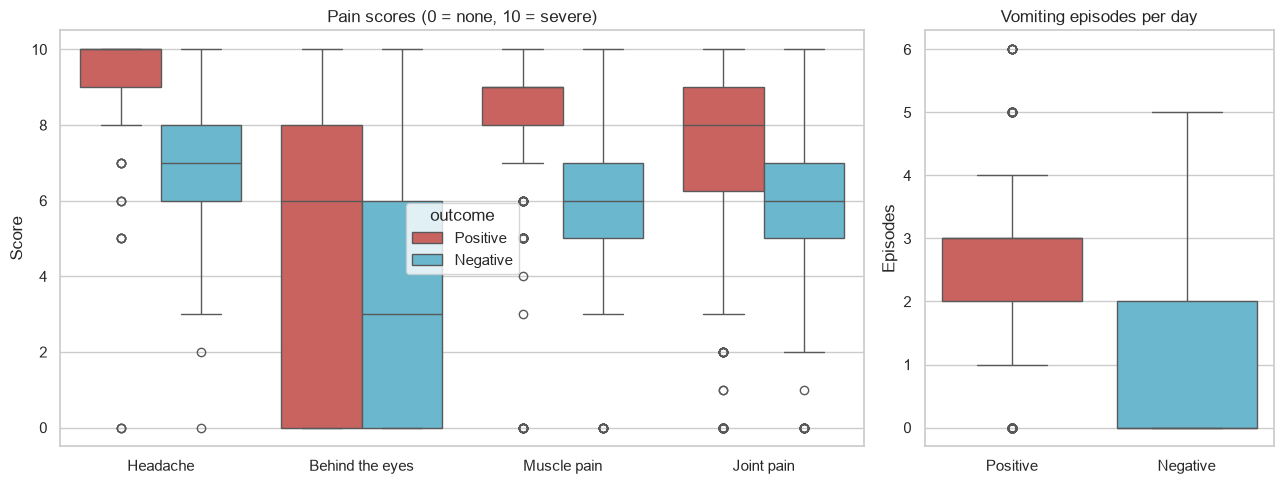

In [44]:
# Short names for the pain scores and a long-format table for grouped boxplots
pain_names = {"headache_severity": "Headache", "retro_orbital_pain": "Behind the eyes",
              "muscle_pain": "Muscle pain", "joint_pain": "Joint pain"}

pain_long = df.melt(id_vars="outcome", value_vars=pain_cols, var_name="symptom", value_name="score")
pain_long["symptom"] = pain_long["symptom"].map(pain_names)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2.3, 1]})

sns.boxplot(data=pain_long, x="symptom", y="score", hue="outcome", hue_order=ORDER,
            palette=COLORS, ax=axes[0])
axes[0].set(title="Pain scores (0 = none, 10 = severe)", xlabel="", ylabel="Score")

sns.boxplot(data=df, x="outcome", y="vomiting_per_day", order=ORDER, hue="outcome",
            palette=COLORS, legend=False, ax=axes[1])
axes[1].set(title="Vomiting episodes per day", xlabel="", ylabel="Episodes")

plt.tight_layout()
plt.show()

**Finding:** Positive participants reported higher median pain scores for all four measures: headache 10 vs 7, muscle pain 9 vs 6, joint pain 8 vs 6 and behind the eyes 6 vs 3. They also reported more vomiting episodes per day (median 3 vs 0). The IQR of each score is shown in the median (IQR) table above, for example headache 10 (1) vs 7 (2). The groups overlap, so these are tendencies and not a rule that separates the groups.

### 8.5 RQ4: Exposure Factors

For every category, the share of dengue-positive participants is shown together with the group size. "Not sure" is kept as its own category (grey) and is not merged into "No".

In [45]:
# Exposure variables and their display names
exposures = {
    "household_dengue_exposure_14d": "Dengue case in household (14 days)",
    "stagnant_water": "Stagnant water nearby",
    "area_type": "Area type",
    "ever_dengue": "Previous dengue infection",
}

# For each category: group size, number of positives and positive percentage
tables = []
for col, title in exposures.items():
    g = df.groupby(df[col].map(english))["outcome"].agg(
        n="size", positive=lambda s: (s == "Positive").sum())
    g["positive_%"] = (g["positive"] / g["n"] * 100).round(2)
    g = g.reset_index().rename(columns={col: "category"})
    g.insert(0, "factor", title)
    tables.append(g)

rq4 = pd.concat(tables, ignore_index=True)
rq4

,factor,category,n,positive,positive_%
0,Dengue case in household (14 days),No,764,451,59.03
1,Dengue case in household (14 days),Not sure,7,5,71.43
2,Dengue case in household (14 days),Yes,247,174,70.45
3,Stagnant water nearby,No,173,89,51.45
4,Stagnant water nearby,Not sure,98,70,71.43
5,Stagnant water nearby,Yes,747,471,63.05
6,Area type,City Corporation / Urban Area,837,526,62.84
7,Area type,Municipality / Semi-urban Area,96,53,55.21
8,Area type,Village / Rural Area,85,51,60.00
9,Previous dengue infection,No,954,585,61.32


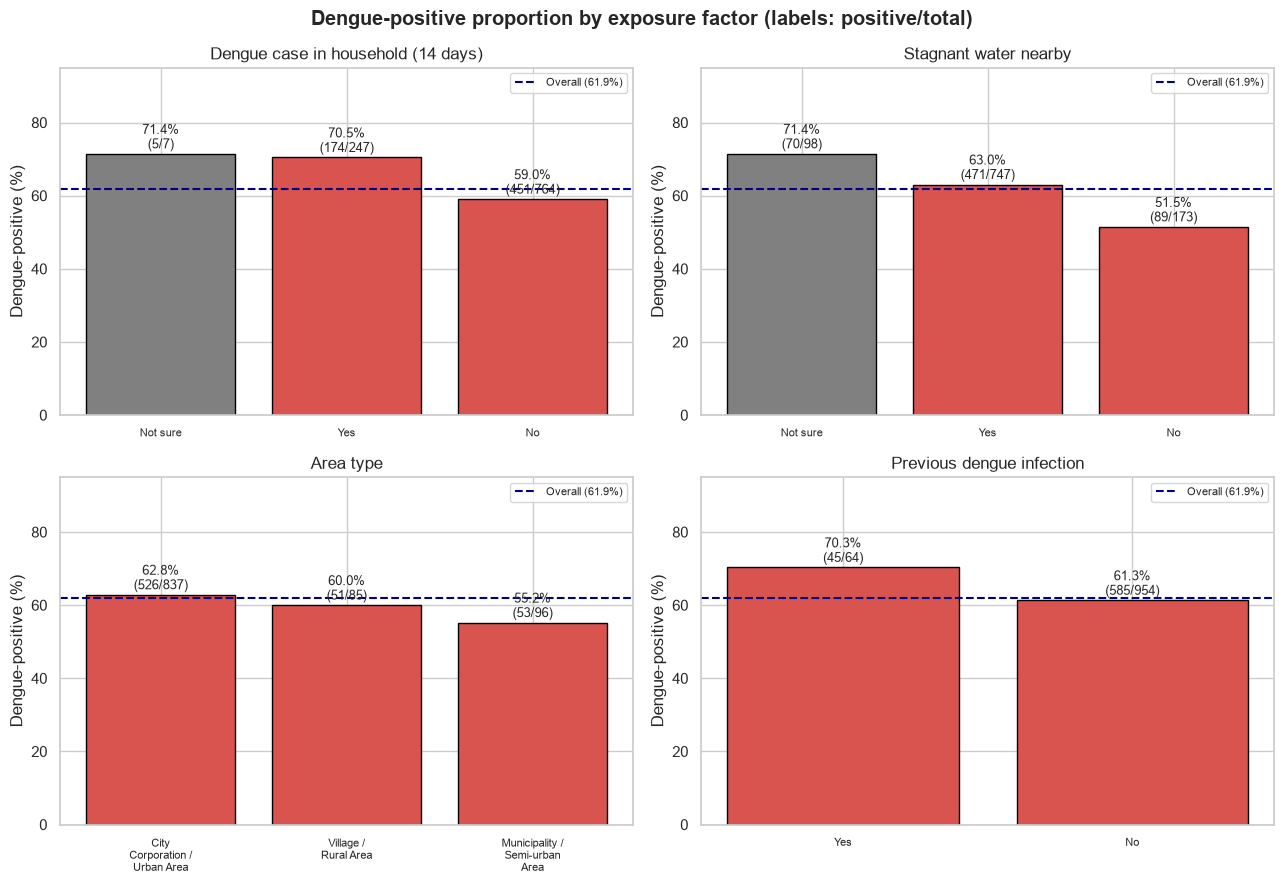

In [46]:
# One bar chart per exposure factor; the dashed line is the overall positive percentage
overall = (df["outcome"] == "Positive").mean() * 100
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (factor, g) in zip(axes.ravel(), rq4.groupby("factor", sort=False)):
    g = g.sort_values("positive_%", ascending=False)
    colors = ["grey" if c.lower().startswith("not sure") else "#d9534f" for c in g["category"]]
    bars = ax.bar([textwrap.fill(c, 14) for c in g["category"]], g["positive_%"], color=colors, edgecolor="black")
    ax.axhline(overall, color="navy", linestyle="--", label=f"Overall ({overall:.1f}%)")
    for bar, pos, n in zip(bars, g["positive"], g["n"]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
                f"{bar.get_height():.1f}%\n({pos}/{n})", ha="center", fontsize=9)
    ax.set(title=factor, ylabel="Dengue-positive (%)", ylim=(0, 95))
    ax.tick_params(axis="x", labelsize=8)
    ax.legend(loc="upper right", fontsize=8)

plt.suptitle("Dengue-positive proportion by exposure factor (labels: positive/total)", fontweight="bold")
plt.tight_layout()
plt.show()

**Findings:**
- **Household case:** 70.5% positive (174/247) when a household case was reported, compared with 59.0% (451/764) when not.
- **Stagnant water:** 63.1% (471/747) with stagnant water, 51.5% (89/173) without. The 98 "Not sure" answers had the highest share (71.4%), so merging them into "No" would change the result.
- **Area type:** Fairly similar: urban 62.8%, rural 60.0%, semi-urban 55.2%.
- **Previous dengue:** 70.3% (45/64) with a previous infection, 61.3% (585/954) without.

These are associations in this sample only. Some groups are small (previous dengue n = 64, rural n = 85, semi-urban n = 96, "Not sure" n = 98), so differences of about 10 points or less should be read with care.

## 9. Preliminary Findings

1. **Fever:** Duration is similar in both groups (median 7 vs 6 days). Peak temperature is higher in the positive group (104 °F vs 102 °F).
2. **Symptoms:** Appetite loss, fatigue and nausea are far more common among positive participants. Abdominal pain, diarrhea and chills are more common among negative participants.
3. **Severity:** All four pain scores and the vomiting count are higher in the positive group.
4. **Exposure:** A household case, stagnant water and a previous infection each go with a higher positive share. Area type shows little difference.

All of this describes the 1,018 participants only. It does not prove cause, does not measure diagnostic accuracy, and is not statistically tested.

## 10. Limitations

- **Self-reported survey data** can have recall and reporting bias. Participants may have known their result before answering.
- **Test results are unverified.** The test type and timing relative to symptom onset are not given.
- **Non-representative sample:** 71% from Dhaka, 75% male, 82% urban, and 11 of 18 districts have fewer than 10 participants. No district-level conclusions are drawn.
- **Temperature quality:** 16 of 1,018 records are not used for the temperature comparison. The 12 missing values are more common in the negative group (8 vs 4), so they cannot be assumed missing at random.
- **"Not sure" answers** (98 and 7) are not clear Yes/No answers, and their handling changes the stagnant-water result.
- **Minors and consent:** 23 participants are under 18 and consent status is not in the public file.
- **Descriptive only:** no confidence intervals, tests or adjustment for other variables.

## 11. Possible Next Steps

1. Add statistical tests with effect sizes and confidence intervals (for example Mann-Whitney U and chi-square), with a correction for multiple comparisons.
2. Repeat the main comparisons with "Not sure" dropped, merged into "No" and kept separate, and with different temperature windows.
3. Ask the dataset authors about the unusual temperature entries, the test type and the survey protocol.
4. Examine age and gender subgroups where the groups are large enough.
5. Consider a predictive model only after proper validation.

## References

1. World Health Organization. (2025). [Dengue and severe dengue: Fact sheet](https://www.who.int/news-room/fact-sheets/detail/dengue-and-severe-dengue).
2. Hasan, M. N., Rahman, M., Uddin, M., et al. (2025). [The 2023 fatal dengue outbreak in Bangladesh highlights a paradigm shift of geographical distribution of cases](https://doi.org/10.1017/S0950268824001791). *Epidemiology and Infection, 153*, e3. Data: Management Information System, Ministry of Health and Family Welfare (DGHS daily dengue press releases).
3. Naim, M. N. I., & Hasan, A. (2026). [Early Detection of Dengue Infection Using Machine Learning: A Survey Dataset from Bangladesh](https://data.mendeley.com/datasets/t2h5528tc4/1) (Version 1). Mendeley Data. https://doi.org/10.17632/t2h5528tc4.1. Licence: CC BY 4.0.